# Step 3: Shape factors

A shape factor = price in a (month, day type, half-hour) divided by that month's baseload. A factor of 1.3 means that half-hour is 30% dearer than the month's average. We estimate them per year, check they're stable, then average and smooth them.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

In [3]:
from gbpricing.features import add_time_features
from gbpricing.holidays import load_bank_holidays

hols = load_bank_holidays(DATA / "raw/bank_holidays.json")
prices = add_time_features(pd.read_parquet(DATA / "processed/mid_clean.parquet"), hols)
print(f"{len(prices):,} half-hours, {prices['settlement_date'].min():%d %b %Y} to {prices['settlement_date'].max():%d %b %Y}")

52,608 half-hours, 01 Jan 2023 to 31 Dec 2025


In [4]:
from gbpricing.shaping import shape_factors_by_year, smooth_shape_factors, stability

by_year = shape_factors_by_year(prices, method="ratio")
st = stability(by_year)
st.pivot(index="month_of_year", columns="day_type", values="mean_pair_corr").round(2)

day_type,weekday,weekend
month_of_year,,
1,0.90,0.90
2,0.95,0.93
3,0.91,0.79
4,0.94,0.82
5,0.82,0.89
6,0.96,0.91
7,0.87,0.62
8,0.95,0.94
9,0.94,0.85


## How stable are the factors across years?

Correlation near 1 = the shape repeats every year, so history is a reasonable guide. Low values flag months where the shape changed, e.g. as solar grew.

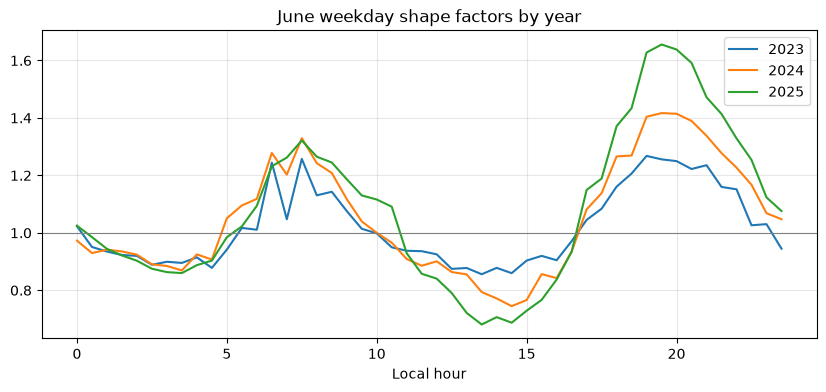

In [5]:
import numpy as np
fig, ax = plt.subplots()
for year, g in by_year[(by_year.month_of_year == 6) & (by_year.day_type == "weekday")].groupby("year"):
    ax.plot(g["slot"] / 2, g["shape_factor"], label=str(year))
ax.axhline(1, color="grey", lw=0.8)
ax.set_title("June weekday shape factors by year"); ax.set_xlabel("Local hour"); ax.legend()
plt.savefig(FIG / "03_june_by_year.png", dpi=150, bbox_inches="tight")

## Average and smooth

Average across years, then a 3-slot rolling mean that wraps around midnight. Smoothing removes noise but too much flattens real features like the evening peak, so compare the two lines.

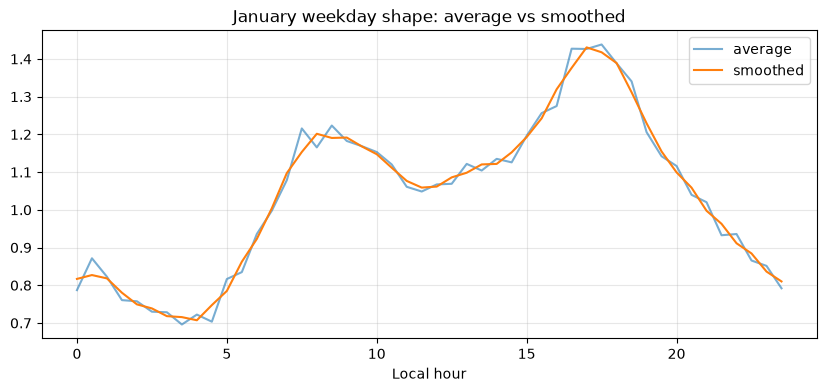

In [6]:
smooth = smooth_shape_factors(by_year, window=3)
raw_avg = by_year.groupby(["month_of_year", "day_type", "slot"])["shape_factor"].mean().reset_index()
sel = lambda d: d[(d.month_of_year == 1) & (d.day_type == "weekday")]
fig, ax = plt.subplots()
ax.plot(sel(raw_avg)["slot"] / 2, sel(raw_avg)["shape_factor"], label="average", alpha=0.6)
ax.plot(sel(smooth)["slot"] / 2, sel(smooth)["shape_factor"], label="smoothed")
ax.set_title("January weekday shape: average vs smoothed"); ax.set_xlabel("Local hour"); ax.legend()
plt.savefig(FIG / "03_smoothing.png", dpi=150, bbox_inches="tight")

## Ratio vs additive

Compare with the additive method (price minus monthly base). Which would you trust in a month where baseload was near zero?

In [7]:
add = smooth_shape_factors(shape_factors_by_year(prices, method="additive"))
add[(add.month_of_year == 1) & (add.day_type == "weekday")].set_index("slot")["shape_factor"].describe().round(2)

count    48.00
mean      4.66
std      22.81
min     -32.01
25%     -18.06
50%       9.37
75%      19.39
max      48.30
Name: shape_factor, dtype: float64

## What I found

- Shape factors remain more stable on weekdays than weekends
- solar peaks have become cheaper whilst evening peaks have become dearer
- you should use additive when baseload approaches zero as ratios won't work

In [8]:
st_pivot = st.pivot(index="month_of_year", columns="day_type", values="mean_pair_corr")
print("Average year-to-year correlation:\n", st_pivot.mean().round(2))
print("Least stable months:\n", st_pivot.min().round(2), st_pivot.idxmin())

jun = by_year[(by_year.month_of_year == 6) & (by_year.day_type == "weekday")]
print(jun[jun.slot.isin([26, 36])].pivot(index="year", columns="slot", values="shape_factor")
      .rename(columns={26: "13:00 midday", 36: "18:00 evening"}).round(2))

Average year-to-year correlation:
 day_type
weekday    0.93
weekend    0.87
dtype: float64
Least stable months:
 day_type
weekday    0.82
weekend    0.62
dtype: float64 day_type
weekday    5
weekend    7
dtype: int64
slot  13:00 midday  18:00 evening
year                             
2023          0.88           1.16
2024          0.86           1.27
2025          0.72           1.37
